# 固定形状计算图：捕获一次，更新输入后重放

目标：将同一小型动作头的多次算子提交收进一个静态计算图，检查新输入是否真正生效，比较稳态延迟并估算准备成本的回本次数。没有训练或任务评估。

PyTorch［张量计算框架］在 NVIDIA［英伟达］和受支持的 ROCm［AMD开放计算平台］设备上沿用 `torch.cuda` 接口。下方打印实际后端；当前执行结果只对应打印的设备。固定图重放与04中的原生条件循环是两个层次。

## 准备相同权重、输入和同步计时器

**本次原生设备实测：0.04053 → 0.03937 毫秒，1.029倍；计时单位为每次小型动作头调用。正确性检查通过。**


In [1]:
from pathlib import Path
import json, hashlib, platform, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the course root from a source or exported notebook directory.
COURSE = next(p for p in [Path.cwd(), *Path.cwd().parents]
              if (p / "reproducibility/task-catalog.json").is_file())
EVIDENCE = COURSE / "notebooks/results/acceleration"
plt.rcParams.update({"figure.figsize": (8, 3.5), "font.size": 11})
print({"python": platform.python_version(), "evidence": str(EVIDENCE)})

import torch
torch.manual_seed(7)
torch.set_num_threads(2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_record = {"torch": torch.__version__, "hip": torch.version.hip,
                 "device": str(DEVICE),
                 "name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else platform.processor(),
                 "scope": "small fixed random action-head exercise; no robot policy or task score"}
display(device_record)
# Six-dimensional observation -> twenty seven-dimensional actions.
model = torch.nn.Sequential(torch.nn.Linear(6, 128), torch.nn.ReLU(),
                            torch.nn.Linear(128, 128), torch.nn.ReLU(),
                            torch.nn.Linear(128, 140)).to(DEVICE).eval()
observation = np.array([[0.1, -0.2, 0.3, 0.0, 0.1, -0.1]], dtype=np.float32)
mean = np.array([[0.0, 0.1, 0.2, 0.0, 0.0, 0.0]], dtype=np.float32)
scale = np.array([[0.2, 0.3, 0.1, 1.0, 1.0, 1.0]], dtype=np.float32)
def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def paired_timings(functions, repeats=5, calls=100):
    # Alternate order to limit warm-cache and temperature order effects.
    samples = {name: [] for name in functions}
    for f in functions.values():
        for _ in range(8):
            f()
    synchronize()
    for repeat in range(repeats):
        names = list(functions)
        if repeat % 2:
            names.reverse()
        for name in names:
            synchronize()
            start = time.perf_counter()
            for _ in range(calls):
                functions[name]()
            synchronize()
            samples[name].append((time.perf_counter() - start) * 1000 / calls)
    return samples

print(json.loads((EVIDENCE / "amd-device-20261028-v1/device.json").read_text()))


{'python': '3.10.19', 'evidence': '/dev/shm/amd-acceleration-20261028-v1/course/notebooks/results/acceleration'}


{'torch': '2.11.0+rocm7.13.0a20260425',
 'hip': '7.13.26162',
 'device': 'cuda',
 'name': 'Radeon 8060S Graphics',
 'scope': 'small fixed random action-head exercise; no robot policy or task score'}

{'hostname': 'aup-NucBox-EVO-X2', 'python': '3.10.19 (main, Oct 21 2025, 16:43:05) [GCC 11.2.0]', 'torch': '2.11.0+rocm7.13.0a20260425', 'hip': '7.13.26162', 'gpu': 'Radeon 8060S Graphics', 'remote_reported_time': '2026-10-29T03:40:02.777923+08:00', 'work_mount': '/dev/shm', 'work_free_bytes': 18131025920, 'scope': 'shared AMD device; other services left running; no training or robot task evaluation'}


## 捕获与输入更新
捕获时保持形状、地址和控制流固定。每次重放前将当前输入复制到静态缓冲区；后续重放会覆盖输出缓冲区，需要长期保存时使用 `clone()`。准备耗时包含侧流预热与捕获。

In [2]:
graph_result = {"executed": False, "reason": "A supported GPU is required; no graph timing on CPU."}
if DEVICE.type == "cuda":
    with torch.inference_mode():
        static_input = torch.as_tensor(observation, device=DEVICE).clone()
        host_input = torch.from_numpy(observation)
        def eager():
            static_input.copy_(host_input)
            return model(static_input)
        started = time.perf_counter()
        warmup_stream = torch.cuda.Stream()
        warmup_stream.wait_stream(torch.cuda.current_stream())
        with torch.cuda.stream(warmup_stream):
            for _ in range(10):
                model(static_input)
        torch.cuda.current_stream().wait_stream(warmup_stream)
        synchronize()
        graph = torch.cuda.CUDAGraph()
        with torch.cuda.graph(graph):
            graph_output = model(static_input)
        synchronize()
        setup_ms = (time.perf_counter() - started) * 1000
        def replay():
            static_input.copy_(host_input)
            graph.replay()
            return graph_output
        errors = []
        for delta in [0.0, 0.125]:
            host_input.copy_(torch.from_numpy(observation + delta))
            expected = eager().clone()
            actual = replay().clone()
            torch.testing.assert_close(expected, actual, atol=1e-6, rtol=1e-5)
            errors.append((expected-actual).abs().max().item())
        host_input.copy_(torch.from_numpy(observation))
        samples = paired_timings({"Eager dispatch": eager, "Graph replay": replay})
        medians = {k: float(np.median(v)) for k, v in samples.items()}
        saved_ms = medians["Eager dispatch"] - medians["Graph replay"]
        graph_result = {"executed": True, "device": device_record, "setup_ms": setup_ms,
                        "median_ms": medians, "raw_round_ms": samples,
                        "two_input_max_abs_errors": errors,
                        "speed_ratio": medians["Eager dispatch"] / medians["Graph replay"],
                        "break_even_calls": int(np.ceil(setup_ms / saved_ms)) if saved_ms > 0 else None}
display(graph_result)


{'executed': True,
 'device': {'torch': '2.11.0+rocm7.13.0a20260425',
  'hip': '7.13.26162',
  'device': 'cuda',
  'name': 'Radeon 8060S Graphics',
  'scope': 'small fixed random action-head exercise; no robot policy or task score'},
 'setup_ms': 66.74419401679188,
 'median_ms': {'Eager dispatch': 0.040528030367568135,
  'Graph replay': 0.039372630417346954},
 'raw_round_ms': {'Eager dispatch': [0.039873430505394936,
   0.040528030367568135,
   0.04078791942447424,
   0.04037191974930465,
   0.04085842985659838],
  'Graph replay': [0.03932981984689832,
   0.03932642983272672,
   0.03959263092838228,
   0.039372630417346954,
   0.03963272087275982]},
 'two_input_max_abs_errors': [0.0, 0.0],
 'speed_ratio': 1.0293452567932095,
 'break_even_calls': 57768}

## 比较准备成本与稳态延迟

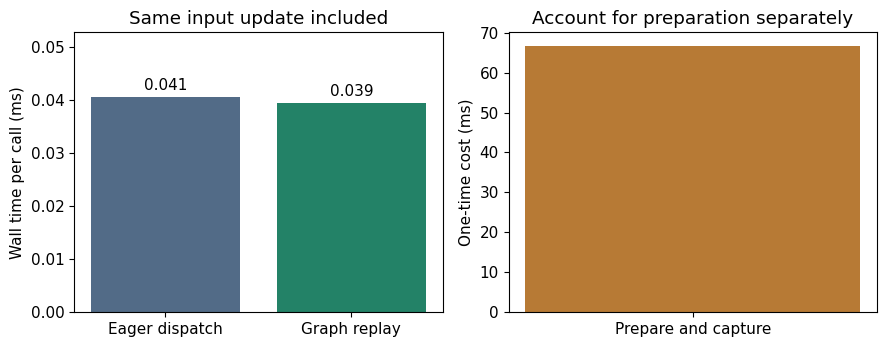

In [3]:
if graph_result["executed"]:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    values = graph_result["median_ms"]
    axes[0].bar(values.keys(), values.values(), color=["#526b87", "#238267"])
    axes[0].bar_label(axes[0].containers[0], fmt="%.3f", padding=3)
    axes[0].set(ylabel="Wall time per call (ms)", title="Same input update included", ylim=(0,max(values.values())*1.3))
    axes[1].bar(["Prepare and capture"], [graph_result["setup_ms"]], color="#b77a35")
    axes[1].set(ylabel="One-time cost (ms)", title="Account for preparation separately")
    fig.tight_layout(); plt.show()
else:
    print(graph_result["reason"])


## 检查与练习
1. 保留两组不同输入的检查，证明重放没有一直使用旧观测。
2. 修改隐藏层宽度后重新捕获，再测量；形状变化需要重新捕获。
3. 将均值和缩放常量作为设备缓冲区，把01的数据准备整合进图；仍把输入复制包含在计时内。

实际策略若含动态形状、数据相关分支或主机同步，需要先解决这些调用契约。04展示设备端条件节点如何处理求解器收敛循环。